In [4]:
import pandas as pd
df = pd.read_csv(
    r"C:\Users\ABHILASH\Downloads\employee_salary_regression.csv"
)
df.head()

,employee_id,age,years_experience,education_level,job_role,city_tier,performance_score,num_skills,remote_work,annual_salary_usd
0,EMP0001,29,9,Master,Software Engineer,1,2.4,3,0,106343.31
1,EMP0002,27,6,Bachelor,ML Engineer,3,2.1,5,1,82852.60
2,EMP0003,36,13,Master,Data Analyst,1,4.1,7,1,142019.59
3,EMP0004,43,23,High School,DevOps,1,3.1,7,1,159972.80
4,EMP0005,24,1,High School,DevOps,1,3.7,12,1,94126.86


In [6]:
df.shape

(1000, 10)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   employee_id        1000 non-null   str    
 1   age                1000 non-null   int64  
 2   years_experience   1000 non-null   int64  
 3   education_level    1000 non-null   str    
 4   job_role           1000 non-null   str    
 5   city_tier          1000 non-null   int64  
 6   performance_score  1000 non-null   float64
 7   num_skills         1000 non-null   int64  
 8   remote_work        1000 non-null   int64  
 9   annual_salary_usd  1000 non-null   float64
dtypes: float64(2), int64(5), str(3)
memory usage: 103.4 KB


In [8]:
df.isnull().sum()

employee_id          0
age                  0
years_experience     0
education_level      0
job_role             0
city_tier            0
performance_score    0
num_skills           0
remote_work          0
annual_salary_usd    0
dtype: int64

In [9]:
df.describe()

,age,years_experience,city_tier,performance_score,num_skills,remote_work,annual_salary_usd
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,40.668000,18.617000,2.046000,3.506200,7.161000,0.488000,137295.111970
std,11.536415,11.634848,0.826176,0.863775,3.103661,0.500106,34692.969621
min,22.000000,0.000000,1.000000,2.000000,2.000000,0.000000,66716.640000
25%,30.000000,8.000000,1.000000,2.800000,4.000000,0.000000,107616.092500
50%,41.000000,19.000000,2.000000,3.500000,7.000000,0.000000,137537.955000
75%,51.000000,29.000000,3.000000,4.300000,10.000000,1.000000,164807.105000
max,60.000000,40.000000,3.000000,5.000000,12.000000,1.000000,217067.540000


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.drop(columns=["employee_id"])
df.head()

,age,years_experience,education_level,job_role,city_tier,performance_score,num_skills,remote_work,annual_salary_usd
0,29,9,Master,Software Engineer,1,2.4,3,0,106343.31
1,27,6,Bachelor,ML Engineer,3,2.1,5,1,82852.60
2,36,13,Master,Data Analyst,1,4.1,7,1,142019.59
3,43,23,High School,DevOps,1,3.1,7,1,159972.80
4,24,1,High School,DevOps,1,3.7,12,1,94126.86


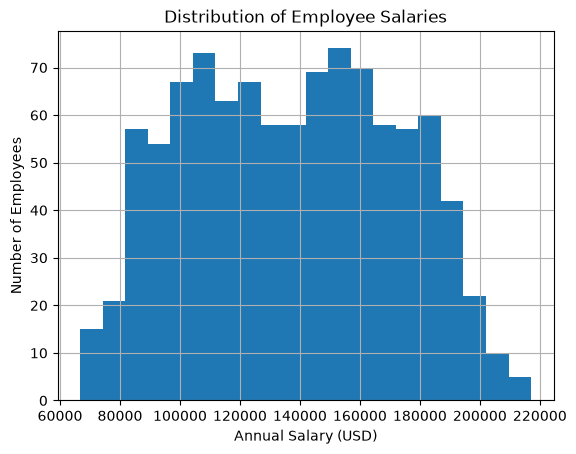

In [12]:
import matplotlib.pyplot as plt
df["annual_salary_usd"].hist(bins=20)
plt.title("Distribution of Employee Salaries")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Number of Employees")
plt.show()

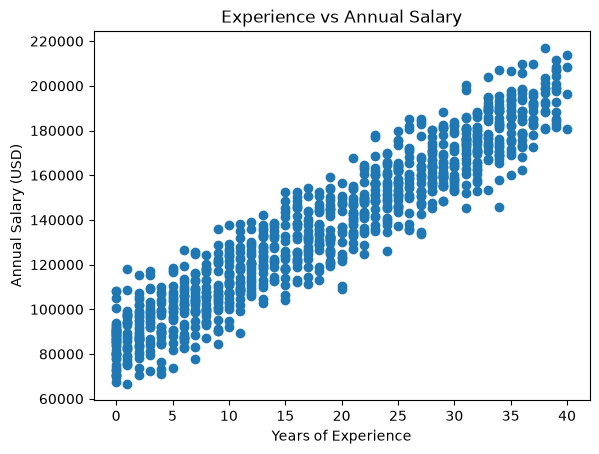

In [13]:
plt.scatter(df["years_experience"], df["annual_salary_usd"])
plt.title("Experience vs Annual Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Annual Salary (USD)")
plt.show()

In [14]:
df.groupby("education_level")["annual_salary_usd"].mean()

education_level
Bachelor       136004.948256
High School    132161.406292
Master         137630.069634
PhD            143086.330781
Name: annual_salary_usd, dtype: float64

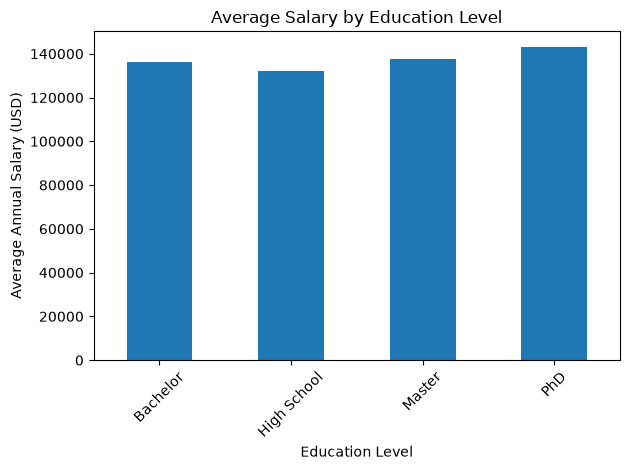

In [15]:

import matplotlib.pyplot as plt

avg_salary = df.groupby("education_level")["annual_salary_usd"].mean()

avg_salary.plot(kind="bar")

plt.title("Average Salary by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Average Annual Salary (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


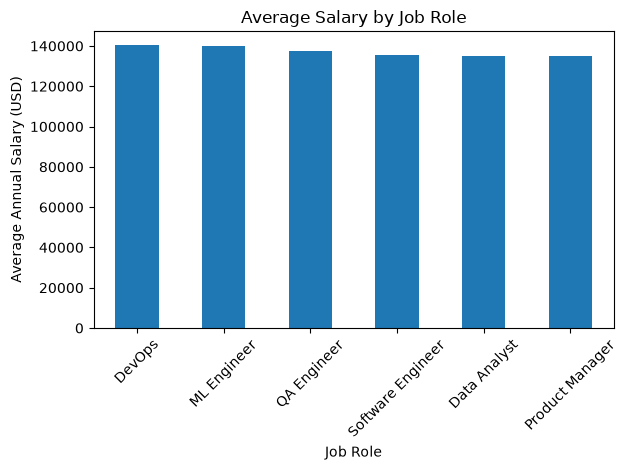

In [16]:

avg_role_salary = df.groupby("job_role")["annual_salary_usd"].mean()

avg_role_salary = avg_role_salary.sort_values(ascending=False)

avg_role_salary.plot(kind="bar")

plt.title("Average Salary by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Average Annual Salary (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [17]:

df[["years_experience", "annual_salary_usd"]].corr()


,years_experience,annual_salary_usd
years_experience,1.000000,0.947786
annual_salary_usd,0.947786,1.000000


In [18]:

X = df.drop(columns=["annual_salary_usd"])
y = df["annual_salary_usd"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (1000, 8)
Target shape: (1000,)


In [19]:

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

X_encoded.head()


,age,years_experience,city_tier,performance_score,num_skills,remote_work,education_level_High School,education_level_Master,education_level_PhD,job_role_DevOps,job_role_ML Engineer,job_role_Product Manager,job_role_QA Engineer,job_role_Software Engineer
0,29,9,1,2.4,3,0,0,1,0,0,0,0,0,1
1,27,6,3,2.1,5,1,0,0,0,0,1,0,0,0
2,36,13,1,4.1,7,1,0,1,0,0,0,0,0,0
3,43,23,1,3.1,7,1,1,0,0,1,0,0,0,0
4,24,1,1,3.7,12,1,1,0,0,1,0,0,0,0


In [20]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 800
Testing rows: 200


In [21]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()


In [22]:

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [23]:

y_pred = model.predict(X_test)

print(y_pred[:10])


[172584.33686879 112551.54229459 161049.07146947  90735.27718831
 180974.12790784  92913.49747177  81300.80843491 147347.83960565
 112860.20692914 140204.3173469 ]


In [24]:

comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})

comparison.head(10)


,Actual Salary,Predicted Salary
0,168471.66,172584.336869
1,112438.67,112551.542295
2,159192.35,161049.071469
3,90415.46,90735.277188
4,178810.86,180974.127908
5,91415.60,92913.497472
6,89375.11,81300.808435
7,152939.73,147347.839606
8,112003.57,112860.206929
9,139257.76,140204.317347


In [25]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))


MAE: 3524.83
RMSE: 4381.87
R2 Score: 0.985


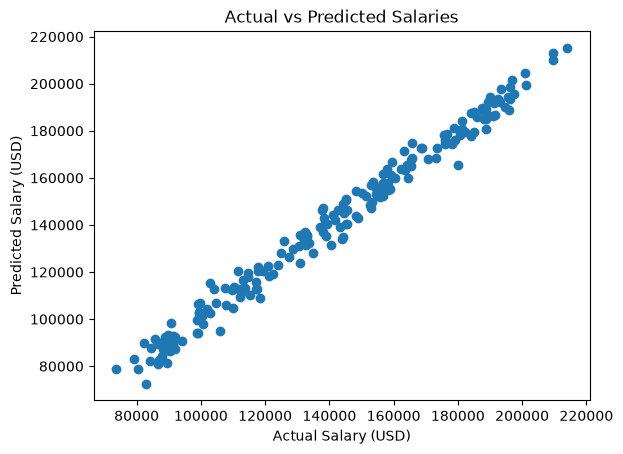

In [26]:

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Salary (USD)")
plt.ylabel("Predicted Salary (USD)")
plt.title("Actual vs Predicted Salaries")

plt.show()


In [27]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Linear Regression MAE:", round(mae, 2))
print("Baseline MAE:", round(baseline_mae, 2))


Linear Regression MAE: 3524.83
Baseline MAE: 31568.21


In [28]:

coefficients = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute_Coefficient"] = coefficients["Coefficient"].abs()

coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
).head(10)


,Feature,Coefficient,Absolute_Coefficient
2,city_tier,-8033.171800,8033.171800
8,education_level_PhD,6271.750989,6271.750989
3,performance_score,6142.958170,6142.958170
6,education_level_High School,-3935.000230,3935.000230
5,remote_work,3196.327772,3196.327772
7,education_level_Master,2930.737101,2930.737101
1,years_experience,2741.897314,2741.897314
4,num_skills,1236.541586,1236.541586
12,job_role_QA Engineer,-437.032557,437.032557
11,job_role_Product Manager,-200.713705,200.713705


In [29]:
%pip install joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [30]:
import joblib

joblib.dump(model, "salary_model.pkl")
joblib.dump(X_encoded.columns.tolist(), "salary_features.pkl")

print("Model saved successfully!")

Model saved successfully!


In [31]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\ABHILASH
['.anaconda', '.antigravity-ide', '.bash_history', '.cache', '.cagent', '.cline', '.codeium', '.conda', '.config', '.copilot', '.cursor', '.devin', '.devin-shared', '.docker', '.eclipse', '.gemini', '.git-for-windows-updater', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lemminx', '.m2', '.p2', '.streamlit', '.VirtualBox', '.virtual_documents', '.vscode', '.vscode-shared', '.zenmap', 'AND.py', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'employee salary prediction.ipynb', 'Favorites', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TM.blf', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Onl

In [33]:
print(X.columns.tolist())
print(X_encoded.columns.tolist())

['age', 'years_experience', 'education_level', 'job_role', 'city_tier', 'performance_score', 'num_skills', 'remote_work']
['age', 'years_experience', 'city_tier', 'performance_score', 'num_skills', 'remote_work', 'education_level_High School', 'education_level_Master', 'education_level_PhD', 'job_role_DevOps', 'job_role_ML Engineer', 'job_role_Product Manager', 'job_role_QA Engineer', 'job_role_Software Engineer']


In [1]:

import os

print("Current folder:", os.getcwd())
print("\nFiles in this folder:")
print(os.listdir())


Current folder: C:\Users\ABHILASH

Files in this folder:
['.anaconda', '.antigravity-ide', '.bash_history', '.cache', '.cagent', '.cline', '.codeium', '.conda', '.config', '.copilot', '.cursor', '.devin', '.devin-shared', '.docker', '.eclipse', '.gemini', '.git-for-windows-updater', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lemminx', '.m2', '.p2', '.streamlit', '.VirtualBox', '.virtual_documents', '.vscode', '.vscode-shared', '.zenmap', 'AND.py', 'app.py', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'employee salary prediction.ipynb', 'Favorites', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TM.blf', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{01277b4e-650e-11ef-891d-9cda3ed3f2fc}.TMContainer0000000000000000

In [1]:

%%writefile C:\Users\ABHILASH\app.py

import streamlit as st
import pandas as pd
import joblib

MODEL_PATH = r"C:\Users\ABHILASH\salary_model.pkl"
FEATURE_PATH = r"C:\Users\ABHILASH\salary_features.pkl"

model = joblib.load(MODEL_PATH)
feature_names = joblib.load(FEATURE_PATH)

st.set_page_config(
    page_title="Employee Salary Prediction",
    page_icon="💼"
)

st.title("Employee Salary Prediction")
st.write("Enter employee details to estimate annual salary.")

with st.form("salary_form"):

    age = st.number_input(
        "Age", min_value=18, max_value=65, value=25
    )

    experience = st.number_input(
        "Years of Experience",
        min_value=0, max_value=40, value=2
    )

    education = st.selectbox(
        "Education Level",
        ["Bachelor", "High School", "Master", "PhD"]
    )

    job_role = st.selectbox(
        "Job Role",
        [
            "Data Analyst",
            "DevOps",
            "ML Engineer",
            "Product Manager",
            "QA Engineer",
            "Software Engineer"
        ]
    )

    city_tier = st.selectbox("City Tier", [1, 2, 3])

    performance = st.number_input(
        "Performance Score",
        min_value=1.0, max_value=5.0, value=3.0
    )

    num_skills = st.number_input(
        "Number of Skills",
        min_value=1, max_value=20, value=5
    )

    remote_work = st.selectbox(
        "Remote Work", ["No", "Yes"]
    )

    submitted = st.form_submit_button("Predict Salary")

if submitted:

    employee = pd.DataFrame([{
        "age": age,
        "years_experience": experience,
        "education_level": education,
        "job_role": job_role,
        "city_tier": city_tier,
        "performance_score": performance,
        "num_skills": num_skills,
        "remote_work": 1 if remote_work == "Yes" else 0
    }])

    encoded = pd.get_dummies(
        employee, drop_first=True, dtype=int
    )

    encoded = encoded.reindex(
        columns=feature_names, fill_value=0
    )

    prediction = model.predict(encoded)[0]

    st.success(
        f"Estimated Annual Salary: ${prediction:,.2f}"
    )

    st.caption(
        "This is an estimate, not a guaranteed salary."
    )


Overwriting C:\Users\ABHILASH\app.py


In [ ]:

!python -m streamlit run "C:\Users\ABHILASH\app.py"
